# Azeitona e azeite em Portugal: análise exploratória inicial
**Estágio de Iniciação Científica 2026/27 – S1 (UPB)** · tarefa T2 (limpeza, harmonização e exploração)

O que este notebook faz:
1. Lê os 4 CSVs exportados do INE (**não precisa renomear**: ele reconhece cada arquivo pelo título).
2. Junta tudo numa tabela única por **região agrária × ano**.
3. Faz verificações de qualidade (anos em falta, somas, consistência entre séries).
4. Faz os primeiros gráficos e a análise de alternância produtiva.
5. Deixa pronta a função de **correlação cruzada** para quando a série de oliveiras estiver disponível.

**Como usar:** coloque os CSVs numa pasta `dados_brutos/` ao lado do notebook (ou na mesma pasta dele) e rode as células em ordem.

In [1]:
import re, glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": .3})
pd.options.display.float_format = "{:,.2f}".format

# pasta com os CSVs: tenta "dados_brutos/" e, se não existir, a pasta atual
DATA_DIR = "dados_brutos" if os.path.isdir("dados_brutos") else "."
OUT_DIR = "dados_tratados"
os.makedirs(OUT_DIR, exist_ok=True)
print("Lendo CSVs de:", os.path.abspath(DATA_DIR))

Lendo CSVs de: /Users/juliajgmb/Documents/GitHub/IC_azeite/dados_brutos


## 1. Leitura dos arquivos do INE
Os CSVs do INE têm cabeçalhos longos, notas no rodapé e dois formatos diferentes (anos nas colunas ou anos nas linhas). As funções abaixo tratam isso e devolvem uma tabela "longa": `ano, regiao, variavel, valor`.

Duas coisas dos arquivos:
- `- -` significa **sem dado** (Açores e Madeira antes de 2005 na série de azeitona).
- Alguns valores vêm com `*` (ex.: `45443 *`). O INE marca assim valores com alguma ressalva; **confirme o significado na metainformação do quadro**. Aqui o `*` é removido do número e guardado na coluna `flag_asterisco`.

In [2]:
VARIAVEIS = {  # texto do título -> nome curto da variável (a ordem importa)
    "Azeite produzido por quintal": "rendimento_hl_q",
    "Azeite produzido (hl)":        "azeite_hl",
    "Azeitona oleificada":          "azeitona_oleificada_t",
    "Produção de azeitona":         "azeitona_producao_t",
}
RE_REGIAO = re.compile(r"^\s*(PT|\d)\s*:\s*(.+?)\s*$")

def ler_linhas(caminho):
    with open(caminho, "rb") as f:
        return f.read().decode("latin-1").splitlines()

def identificar_variavel(linhas):
    topo = " ".join(linhas[:15])
    for chave, nome in VARIAVEIS.items():
        if chave in topo:
            return nome
    return None

def limpar_valor(txt):
    txt = txt.strip()
    flag = "*" in txt
    t = txt.replace("*", "").replace(" ", "")
    if t in {"", "-", "--", "..", "x"}:
        return np.nan, flag
    try:
        return float(t.replace(",", ".")), flag
    except ValueError:
        return np.nan, flag

def _registo(ano, cod_reg, nome_reg, bruto, var):
    v, f = limpar_valor(bruto)
    cod = 0 if cod_reg == "PT" else int(cod_reg)
    return dict(ano=int(ano), regiao_cod=cod, regiao=nome_reg, variavel=var, valor=v, flag_asterisco=f)

def ler_formato_largo(linhas, var):
    """Regiões nas linhas, anos nas colunas."""
    anos, regs = None, []
    for l in linhas:
        c = l.split(";")
        if anos is None:
            ys = [x.strip() for x in c[1:] if x.strip()]
            if len(ys) > 3 and all(re.fullmatch(r"\d{4}", y) for y in ys):
                anos = ys
            continue
        m = RE_REGIAO.match(c[0])
        if m:
            for ano, bruto in zip(anos, c[1:1 + len(anos)]):
                regs.append(_registo(ano, m.group(1), m.group(2), bruto, var))
    return regs

def ler_formato_longo(linhas, var):
    """Anos nas linhas (ano;região;valor)."""
    regs, ano = [], None
    for l in linhas:
        c = l.split(";")
        if len(c) < 3:
            if regs:   # fim da tabela
                break
            continue
        if re.fullmatch(r"\d{4}", c[0].strip()):
            ano = c[0].strip()
        m = RE_REGIAO.match(c[1])
        if ano and m:
            regs.append(_registo(ano, m.group(1), m.group(2), c[2], var))
    return regs

def ler_csv_ine(caminho):
    linhas = ler_linhas(caminho)
    var = identificar_variavel(linhas)
    if var is None:
        return None
    # formato largo: a linha de cabeçalho tem vários anos separados por ";"
    largo = any(re.match(r"^;(\d{4};){5,}", l) for l in linhas[:20])
    regs = ler_formato_largo(linhas, var) if largo else ler_formato_longo(linhas, var)
    return pd.DataFrame(regs)

partes = []
for caminho in sorted(glob.glob(os.path.join(DATA_DIR, "*.csv"))):
    df_i = ler_csv_ine(caminho)
    if df_i is None or df_i.empty:
        print("  (ignorado)", os.path.basename(caminho))
        continue
    print(f"  {df_i['variavel'].iloc[0]:<24} <- {os.path.basename(caminho)}  "
          f"({df_i['ano'].min()}–{df_i['ano'].max()}, {len(df_i)} linhas)")
    partes.append(df_i)

longo = pd.concat(partes, ignore_index=True)
longo.head()

  azeitona_producao_t      <- 1xI7ln-te5Qi0l23aXUQ4smhTQWZQfcgpYergOTd_44657.csv  (1995–2025, 310 linhas)
  azeitona_oleificada_t    <- 1xI7ln-te5Qi0l23aXUQ4smhTQWZQfcgpYergOTd_85616.csv  (1995–2025, 310 linhas)
  rendimento_hl_q          <- 1xI7ln-te5Qi0l23aXUQ4smhTQWZQfcgpYergOTd_93057.csv  (1995–2025, 310 linhas)
  azeite_hl                <- 1xI7ln-te5Qi0l23aXUQ4smhTQWZQfcgpYergOTd_99547.csv  (2004–2025, 220 linhas)
  (ignorado) YDS8aRZLeUAm0YcAXkCAenPfmrwLClOXNfrY6cNM_46347.csv
  (ignorado) YDS8aRZLeUAm0YcAXkCAenPfmrwLClOXNfrY6cNM_73947.csv
  (ignorado) YDS8aRZLeUAm0YcAXkCAenPfmrwLClOXNfrY6cNM_99258.csv


,ano,regiao_cod,regiao,variavel,valor,flag_asterisco
0,2025,0,Portugal,azeitona_producao_t,"1,259,711.00",False
1,2024,0,Portugal,azeitona_producao_t,"1,310,127.00",False
2,2023,0,Portugal,azeitona_producao_t,"1,176,087.00",False
3,2022,0,Portugal,azeitona_producao_t,"774,743.00",False
4,2021,0,Portugal,azeitona_producao_t,"1,350,238.00",False


## 2. Tabela única (painel região × ano)
- **Portugal** (código 0) é o total nacional, guardado à parte.
- Usamos as **7 regiões do Continente** (códigos 1–7). Açores e Madeira ficam de fora: produzem 0 e têm vários anos sem dado.

In [3]:
CONTINENTE = list(range(1, 8))
painel = (longo[longo.regiao_cod.isin(CONTINENTE)]
          .pivot_table(index=["ano", "regiao_cod", "regiao"], columns="variavel", values="valor")
          .reset_index())
painel.columns.name = None

nacional = (longo[longo.regiao_cod == 0]
            .pivot_table(index="ano", columns="variavel", values="valor"))

painel.to_csv(os.path.join(OUT_DIR, "painel_regiao_ano.csv"), index=False)
nacional.to_csv(os.path.join(OUT_DIR, "nacional_ano.csv"))
print("Painel:", painel.shape, "| anos:", painel.ano.min(), "a", painel.ano.max())
painel.head(8)

Painel: (217, 7) | anos: 1995 a 2025


,ano,regiao_cod,regiao,azeite_hl,azeitona_oleificada_t,azeitona_producao_t,rendimento_hl_q
0,1995,1,Entre Douro e Minho,NaN,"2,511.00","2,399.00",0.19
1,1995,2,Trás-os-Montes,NaN,"80,616.00","82,019.00",0.18
2,1995,3,Beira Litoral,NaN,"32,136.00","21,989.00",0.15
3,1995,4,Beira Interior,NaN,"62,322.00","65,847.00",0.14
4,1995,5,Ribatejo e Oeste,NaN,"43,604.00","43,355.00",0.13
5,1995,6,Alentejo,NaN,"80,431.00","87,039.00",0.15
6,1995,7,Algarve,NaN,"9,637.00","8,609.00",0.17
7,1996,1,Entre Douro e Minho,NaN,"6,175.00","6,077.00",0.11


## 3. Verificações de qualidade
Antes de modelar, confirme que os dados estão coerentes.

In [4]:
# 3.1 Cobertura: primeiro e último ano de cada variável
cobertura = longo.dropna(subset=["valor"]).groupby("variavel").ano.agg(["min", "max", "nunique"])
print(cobertura)

                        min   max  nunique
variavel                                  
azeite_hl              2004  2025       22
azeitona_oleificada_t  1995  2025       31
azeitona_producao_t    1995  2025       31
rendimento_hl_q        1995  2025       31


In [5]:
# 3.2 A soma das regiões bate com o total de Portugal? (diferença relativa máxima por variável)
somas = (longo[longo.regiao_cod.between(1, 9)].groupby(["variavel", "ano"]).valor.sum(min_count=1)
         .rename("soma_regioes").reset_index()
         .merge(longo[longo.regiao_cod == 0][["variavel", "ano", "valor"]].rename(columns={"valor": "total_PT"}),
                on=["variavel", "ano"]))
# rendimento (hl/q) é uma razão e não se soma: ignorar
somas = somas[somas.variavel != "rendimento_hl_q"]
somas["dif_%"] = 100 * (somas.soma_regioes - somas.total_PT).abs() / somas.total_PT
print(somas.groupby("variavel")["dif_%"].max().round(3))

variavel
azeite_hl               0.00
azeitona_oleificada_t   0.00
azeitona_producao_t     0.00
Name: dif_%, dtype: float64


In [6]:
# 3.3 Consistência: azeite (hl) ≈ rendimento (hl/q) × azeitona oleificada (t) × 10 (1 t = 10 q)
chk = nacional[["azeite_hl", "rendimento_hl_q", "azeitona_oleificada_t"]].dropna().copy()
chk["azeite_estimado"] = chk.rendimento_hl_q * chk.azeitona_oleificada_t * 10
chk["erro_%"] = 100 * (chk.azeite_estimado - chk.azeite_hl) / chk.azeite_hl
print("Erro relativo (nacional): mínimo %.1f%% | máximo %.1f%%" % (chk["erro_%"].min(), chk["erro_%"].max()))
print("(o rendimento vem arredondado a 2 casas, então algum erro é normal)")

# 3.4 A azeitona oleificada nunca deve passar da produção total
comp = nacional[["azeitona_producao_t", "azeitona_oleificada_t"]].dropna()
print("Anos em que oleificada > produção:", list(comp.index[comp.azeitona_oleificada_t > comp.azeitona_producao_t]))

# 3.5 Valores em falta e com asterisco no painel das 7 regiões
print("\nValores em falta (Continente):")
print(longo[longo.regiao_cod.isin(CONTINENTE)].groupby("variavel").valor.apply(lambda s: s.isna().sum()))
print("Valores com asterisco:")
print(longo[longo.flag_asterisco].groupby(["variavel", "ano", "regiao"]).size())

Erro relativo (nacional): mínimo -2.9% | máximo 2.5%
(o rendimento vem arredondado a 2 casas, então algum erro é normal)
Anos em que oleificada > produção: []

Valores em falta (Continente):
variavel
azeite_hl                0
azeitona_oleificada_t    0
azeitona_producao_t      0
rendimento_hl_q          0
Name: valor, dtype: int64
Valores com asterisco:
variavel             ano   regiao          
azeitona_producao_t  2016  Alentejo            1
                           Ribatejo e Oeste    1
                     2017  Alentejo            1
                           Algarve             1
                           Ribatejo e Oeste    1
dtype: int64


> **Atenção ao período:** a série de **azeite (hl)** que você exportou começa em **2004** (tem uma dimensão extra, "grau de acidez"), enquanto azeitona e rendimento começam em **1995**. Ao juntar tudo, os modelos com azeite terão ~22 anos por região, e os de azeitona ~31. A verificação 3.3 mostra que dá para **reconstruir** o azeite de 1995–2003 a partir de rendimento × azeitona, mas de forma aproximada; só vale a pena se os orientadores concordarem.

## 4. Evolução temporal

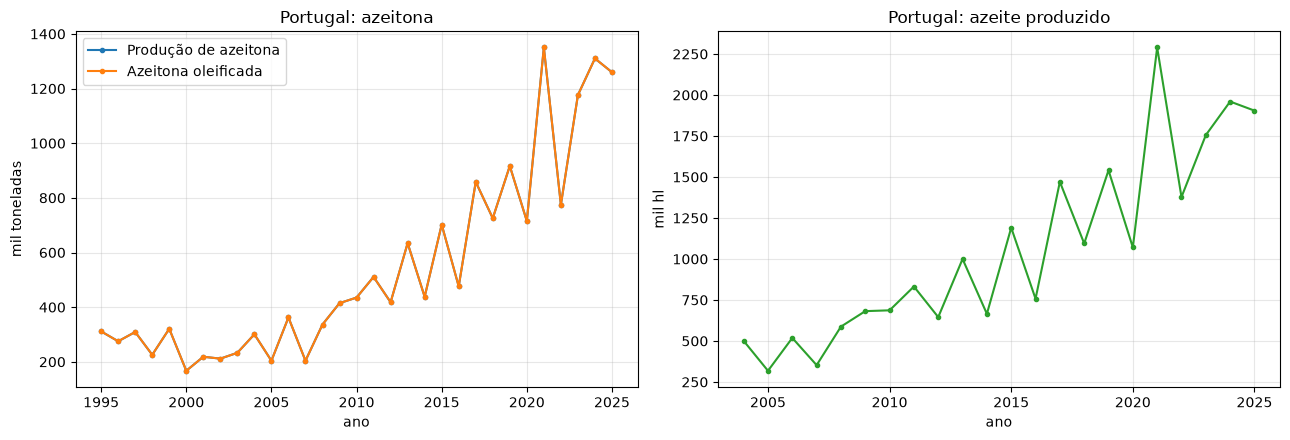

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
nacional["azeitona_producao_t"].div(1e3).plot(ax=ax[0], marker="o", ms=3, label="Produção de azeitona")
nacional["azeitona_oleificada_t"].div(1e3).plot(ax=ax[0], marker="o", ms=3, label="Azeitona oleificada")
ax[0].set(title="Portugal: azeitona", ylabel="mil toneladas", xlabel="ano"); ax[0].legend()

nacional["azeite_hl"].div(1e3).plot(ax=ax[1], marker="o", ms=3, color="tab:green")
ax[1].set(title="Portugal: azeite produzido", ylabel="mil hl", xlabel="ano")
plt.tight_layout(); plt.show()

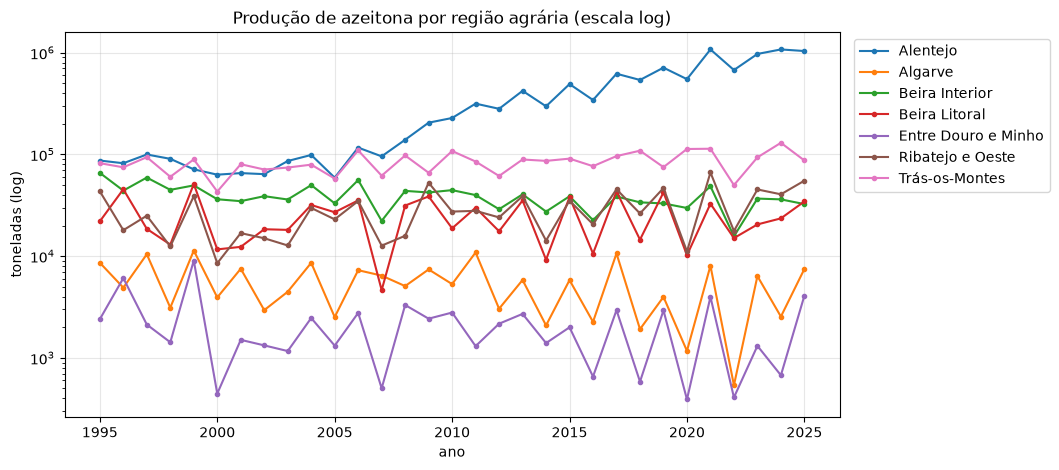

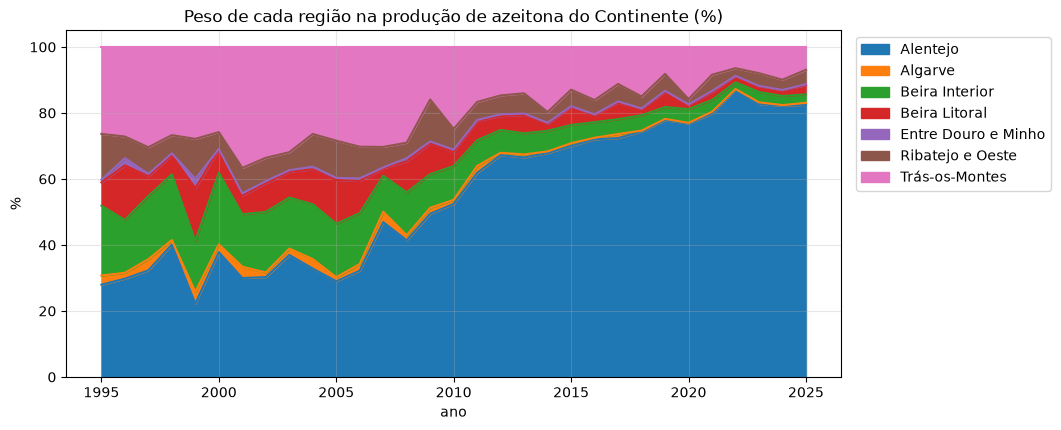

regiao  Alentejo  Algarve  Beira Interior  Beira Litoral  Entre Douro e Minho  \
ano                                                                             
1995       28.00     2.80           21.20           7.10                 0.80   
2025       82.50     0.60            2.60           2.70                 0.30   

regiao  Ribatejo e Oeste  Trás-os-Montes  
ano                                       
1995               13.90           26.40  
2025                4.40            6.90  


In [8]:
# Por região (escala logarítmica: o Alentejo é muito maior que as outras)
az = painel.pivot(index="ano", columns="regiao", values="azeitona_producao_t")
az.plot(logy=True, marker="o", ms=3, figsize=(10, 5), title="Produção de azeitona por região agrária (escala log)")
plt.ylabel("toneladas (log)"); plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left"); plt.show()

# Peso de cada região no total do Continente
peso = az.div(az.sum(axis=1), axis=0) * 100
peso.plot.area(figsize=(10, 4.5), title="Peso de cada região na produção de azeitona do Continente (%)")
plt.ylabel("%"); plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left"); plt.show()
print(peso.loc[[peso.index.min(), peso.index.max()]].round(1))

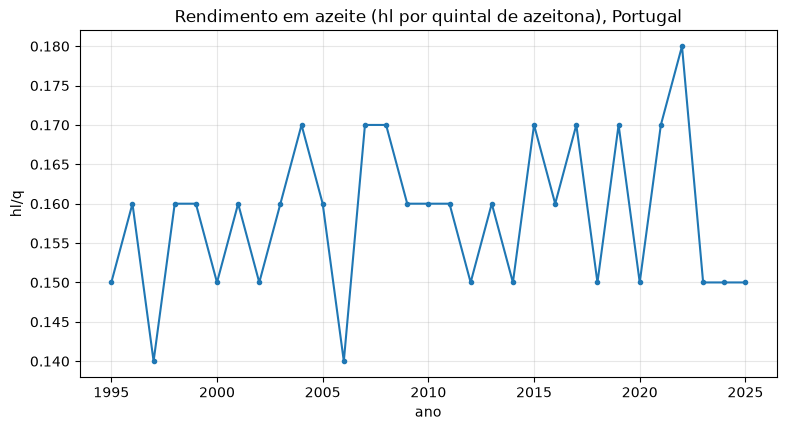

In [9]:
# Rendimento: litros de azeite por quintal de azeitona (nacional)
nacional["rendimento_hl_q"].plot(marker="o", ms=3, title="Rendimento em azeite (hl por quintal de azeitona), Portugal")
plt.ylabel("hl/q"); plt.show()

## 5. Alternância produtiva e anos atípicos
A oliveira tende a alternar anos de produção alta e baixa. Isso pode **esconder** qualquer efeito de longo prazo, e é por isso que o plano inclui a produção do ano anterior e testes de robustez. Abaixo usamos a **variação anual em log** (≈ variação percentual), que remove a tendência.

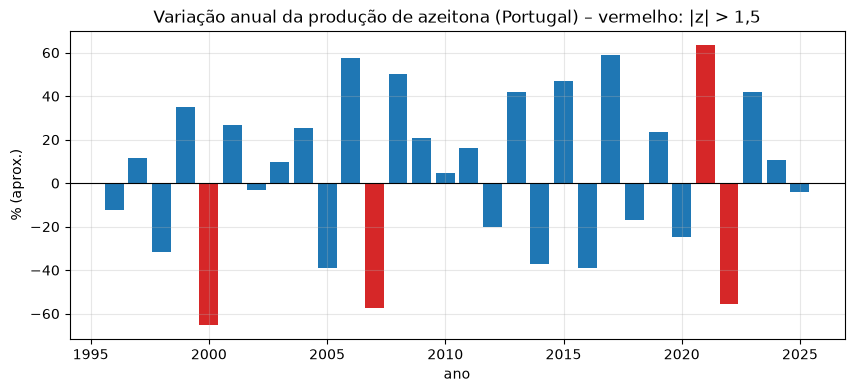

Anos candidatos a 'atípicos' (para o teste de robustez): [2000, 2007, 2021, 2022]

Autocorrelação da variação anual (lags 1 a 5):
1   -0.80
2    0.60
3   -0.39
4    0.24
5   -0.07
dtype: float64


In [10]:
prod = nacional["azeitona_producao_t"].dropna()
cresc = np.log(prod).diff().dropna()          # variação anual em log
z = (cresc - cresc.mean()) / cresc.std()

fig, ax = plt.subplots(figsize=(10, 4))
cores = ["tab:red" if abs(v) > 1.5 else "tab:blue" for v in z]
ax.bar(cresc.index, cresc.values * 100, color=cores)
ax.axhline(0, color="k", lw=.8)
ax.set(title="Variação anual da produção de azeitona (Portugal) – vermelho: |z| > 1,5", ylabel="% (aprox.)", xlabel="ano")
plt.show()

print("Anos candidatos a 'atípicos' (para o teste de robustez):", list(z.index[z.abs() > 1.5]))

# Autocorrelação das variações: valor negativo nos primeiros lags = alternância
ac = pd.Series({k: cresc.autocorr(k) for k in range(1, 6)})
print("\nAutocorrelação da variação anual (lags 1 a 5):"); print(ac.round(2))

## 6. Correlação cruzada (pronta para a série de oliveiras)
A pergunta do projeto é **em que desfasamento** a série de oliveiras antecipa a produção. Esta função calcula a correlação entre `y` no ano *t* e `x` no ano *t − k*.

Nas **variações anuais em log**, e não nos níveis: duas séries crescentes têm correlação alta só por causa da tendência (correlação espúria). Como há poucos anos, trate os resultados como **exploratórios**, não como prova.

In [11]:
def correlacao_cruzada(x, y, max_lag=8):
    """Correlação de y(t) com x(t-k), k = 0..max_lag. x e y: Series indexadas por ano."""
    return pd.Series({k: y.corr(x.shift(k)) for k in range(0, max_lag + 1)}, name="corr")

# Exemplo que já funciona: azeitona oleificada (x) vs azeite (y), variações em log
x = np.log(nacional["azeitona_oleificada_t"]).diff()
y = np.log(nacional["azeite_hl"]).diff()
print(correlacao_cruzada(x, y, 4).round(2))   # esperado: forte no lag 0 (é a mesma matéria-prima)

# ---- QUANDO TIVER A SÉRIE DE OLIVEIRAS (ou área de olival) ----
# oliveiras = pd.read_csv("dados_brutos/oliveiras.csv")        # ajuste ao formato real
# s_oliv = oliveiras.set_index("ano")["valor"]
# x = np.log(s_oliv).diff()
# y = np.log(nacional["azeitona_producao_t"]).diff()
# print(correlacao_cruzada(x, y, 8).round(2))

0    0.98
1   -0.83
2    0.60
3   -0.46
4    0.33
Name: corr, dtype: float64


## 7. Vendas de oliveiras pelos viveiros (variável explicativa)
Fonte: INE, *Inquérito à venda de árvores de fruto e oliveiras*. Um mesmo CSV traz **dois indicadores**:
- colunas por **local de origem** (onde fica o viveiro): total, vendidas diretamente a agricultores, a revendedores, a outros viveiristas e importadas;
- `direto_agr_destino`: oliveiras vendidas **diretamente a agricultores, por local de destino** (onde serão plantadas). **É a variável principal**, porque o viveiro e o olival costumam estar em regiões diferentes.

O notebook lê todos os CSVs de árvores da pasta (se houver mais de um, junta e remove duplicados).

In [12]:
RE_REG_GERAL = re.compile(r"^\s*([0-9A-Z]+)\s*:\s*(.+?)\s*$")
COLS_ARV = ["total_origem", "direto_agr_origem", "revendedores", "outros_viveiristas",
            "importadas", "direto_agr_destino"]

def ler_arvores(caminho):
    linhas = ler_linhas(caminho)
    if "Árvores de fruto e oliveiras vendidas (N.º)" not in " ".join(linhas[:12]):
        return None
    regs, ano, reg = [], None, None
    for l in linhas:
        c = l.split(";")
        if len(c) < 9:
            if regs:
                break
            continue
        if re.fullmatch(r"\d{4}", c[0].strip()):
            ano = int(c[0])
        m = RE_REG_GERAL.match(c[1])
        if m:
            reg = (m.group(1), m.group(2))
        if ano is None or reg is None or not c[2].strip():
            continue
        vals = [limpar_valor(x)[0] for x in c[3:9]]
        regs.append(dict(ano=ano, regiao_cod=reg[0], regiao=reg[1], especie=c[2].strip(),
                         **dict(zip(COLS_ARV, vals))))
    return pd.DataFrame(regs)

partes_arv = [ler_arvores(p) for p in sorted(glob.glob(os.path.join(DATA_DIR, "*.csv")))]
partes_arv = [a for a in partes_arv if a is not None and not a.empty]
assert partes_arv, "Nenhum CSV de árvores encontrado em " + DATA_DIR

arvores = pd.concat(partes_arv).drop_duplicates(["ano", "regiao_cod", "especie"])
oliv = arvores[arvores.especie == "Oliveiras"].copy()          # só oliveiras ("Total" = todas as árvores de fruto)
print("Anos:", oliv.ano.min(), "a", oliv.ano.max())
print("Regiões disponíveis:", sorted(oliv.regiao.unique()))
oliv.to_csv(os.path.join(OUT_DIR, "oliveiras_vendidas.csv"), index=False)
oliv.head()

Anos: 1996 a 2026
Regiões disponíveis: ['Alentejo', 'Algarve', 'Centro', 'Continente', 'Grande Lisboa', 'Norte', 'Oeste e Vale do Tejo', 'Península de Setúbal']


,ano,regiao_cod,regiao,especie,total_origem,direto_agr_origem,revendedores,outros_viveiristas,importadas,direto_agr_destino
1,2026,11,Norte,Oliveiras,"51,901.00","49,770.00","2,131.00",0.00,0.00,"63,894.00"
3,2026,19,Centro,Oliveiras,"446,671.00","74,874.00","204,075.00","159,552.00","8,170.00","48,558.00"
5,2025,11,Norte,Oliveiras,"77,690.00","76,840.00",430.00,420.00,0.00,"182,125.00"
7,2025,19,Centro,Oliveiras,"399,931.00","205,165.00","126,167.00","48,975.00","19,624.00","70,026.00"
9,2024,11,Norte,Oliveiras,"85,210.00","61,697.00","19,626.00",52.00,"3,835.00","162,371.00"


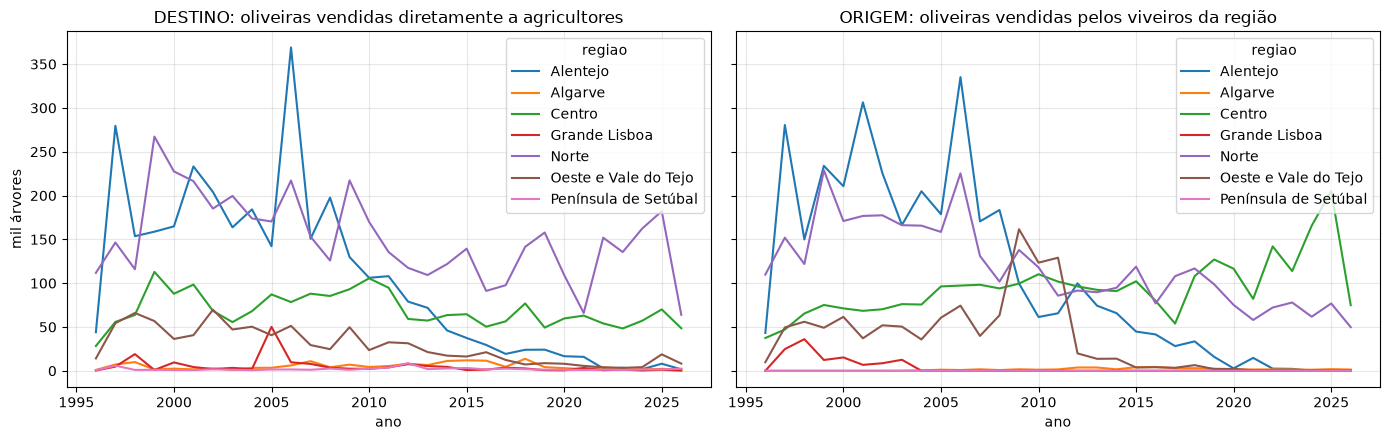

In [13]:
# O que cada região recebe (destino) vs. o que cada região vende (origem)
dest = oliv.pivot(index="ano", columns="regiao", values="direto_agr_destino")
orig = oliv.pivot(index="ano", columns="regiao", values="direto_agr_origem")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
cols = [c for c in dest.columns if c != "Continente"]
(dest[cols] / 1e3).plot(ax=ax[0], title="DESTINO: oliveiras vendidas diretamente a agricultores")
(orig[cols] / 1e3).plot(ax=ax[1], title="ORIGEM: oliveiras vendidas pelos viveiros da região")
for a in ax: a.set(ylabel="mil árvores", xlabel="ano")
plt.tight_layout(); plt.show()

## 8. Árvores vs. produção: primeira comparação
Primeiro no **nível nacional** (Continente), onde a geografia não cria problemas. Depois no **Alentejo** e no **Algarve**, cujas regiões coincidem (ou quase) entre a classificação NUTS 2024 das árvores e a região agrária da produção.

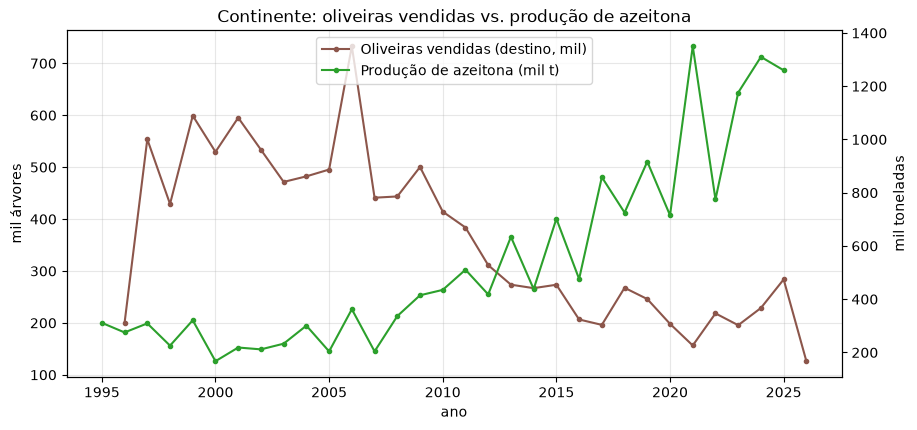

In [14]:
arv_cont = oliv[oliv.regiao_cod == "1"].set_index("ano")["direto_agr_destino"].rename("oliveiras_destino")
nac = nacional.join(arv_cont, how="outer")

fig, ax = plt.subplots(figsize=(10, 4.5))
(nac["oliveiras_destino"] / 1e3).plot(ax=ax, color="tab:brown", marker="o", ms=3, label="Oliveiras vendidas (destino, mil)")
ax.set(ylabel="mil árvores", xlabel="ano")
ax2 = ax.twinx()
(nac["azeitona_producao_t"] / 1e3).plot(ax=ax2, color="tab:green", marker="o", ms=3, label="Produção de azeitona (mil t)")
ax2.set_ylabel("mil toneladas"); ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper center"); ax.set_title("Continente: oliveiras vendidas vs. produção de azeitona")
plt.show()

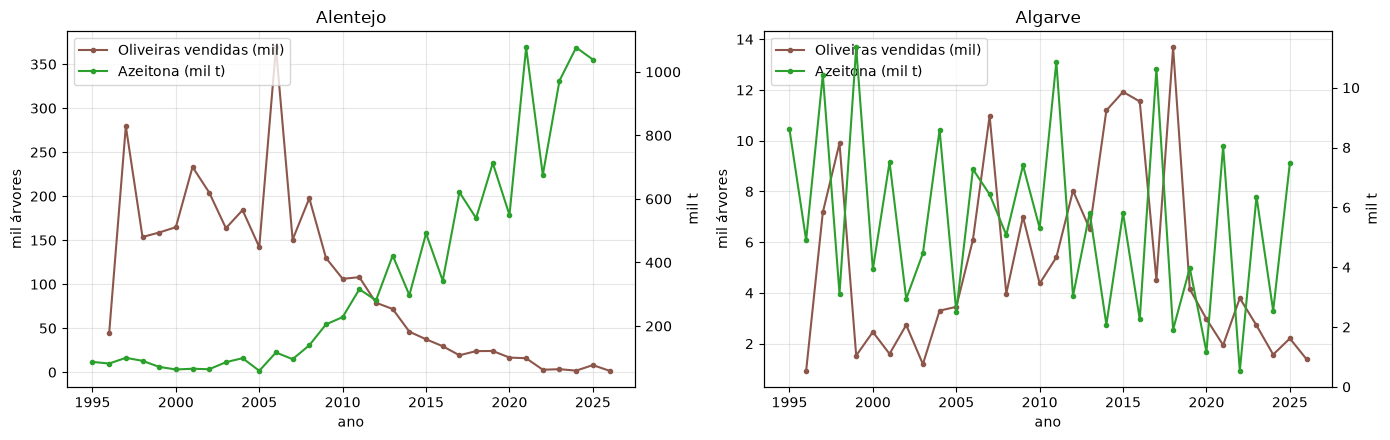

In [15]:
# Alentejo e Algarve: árvores (NUTS 2024) vs azeitona (região agrária)
CASOS = {"Alentejo": "1C", "Algarve": "15"}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, (nome, cod) in zip(ax, CASOS.items()):
    t = oliv[oliv.regiao_cod == cod].set_index("ano")["direto_agr_destino"]
    p = painel[painel.regiao.str.strip() == nome].set_index("ano")["azeitona_producao_t"]
    (t / 1e3).plot(ax=a, color="tab:brown", marker="o", ms=3, label="Oliveiras vendidas (mil)")
    a.set(title=nome, ylabel="mil árvores", xlabel="ano")
    b = a.twinx(); (p / 1e3).plot(ax=b, color="tab:green", marker="o", ms=3, label="Azeitona (mil t)")
    b.set_ylabel("mil t"); b.grid(False)
    h1, l1 = a.get_legend_handles_labels(); h2, l2 = b.get_legend_handles_labels()
    a.legend(h1 + h2, l1 + l2, loc="upper left")
plt.tight_layout(); plt.show()

In [16]:
def log_cresc(s):
    s = s.where(s > 0)                       # evita log(0)
    return np.log(s).diff()

def corr_cruzada(x, y, max_lag=8):
    # correlação entre y(t) e x(t-k): x "antecipa" y em k anos
    return pd.Series({k: y.corr(x.shift(k)) for k in range(0, max_lag + 1)}, name="corr")

resultados = {}
prod_nac = nac["azeitona_producao_t"].dropna()
resultados["Continente"] = corr_cruzada(log_cresc(nac["oliveiras_destino"]), log_cresc(prod_nac))
for nome, cod in CASOS.items():
    t = oliv[oliv.regiao_cod == cod].set_index("ano")["direto_agr_destino"]
    p = painel[painel.regiao.str.strip() == nome].set_index("ano")["azeitona_producao_t"]
    resultados[nome] = corr_cruzada(log_cresc(t), log_cresc(p))

print("Correlação entre a variação anual da produção de azeitona (t) e a variação das vendas de oliveiras (t-k)")
print(pd.DataFrame(resultados).round(2))

# Em níveis (cuidado: duas séries com tendência dão correlações enganadoras)
niv = pd.Series({k: nac["azeitona_producao_t"].corr(nac["oliveiras_destino"].shift(k)) for k in range(0, 9)})
print("\nCorrelação em NÍVEIS (Continente), só para referência:"); print(niv.round(2).to_string())

Correlação entre a variação anual da produção de azeitona (t) e a variação das vendas de oliveiras (t-k)
   Continente  Alentejo  Algarve
0        0.20      0.41    -0.34
1       -0.40     -0.36     0.39
2        0.26      0.40    -0.36
3       -0.27     -0.37     0.43
4        0.05      0.43    -0.41
5        0.03     -0.24     0.25
6       -0.13      0.36    -0.09
7        0.26     -0.41    -0.15
8       -0.46      0.43     0.23

Correlação em NÍVEIS (Continente), só para referência:
0   -0.70
1   -0.77
2   -0.72
3   -0.74
4   -0.71
5   -0.68
6   -0.67
7   -0.62
8   -0.67


> **Leia isto antes de interpretar:** nesta série, as vendas de oliveiras a agricultores **caem** (de ~500 mil/ano nos anos 2000 para ~200 mil), e o **Alentejo, que concentra a produção de azeitona, quase deixa de aparecer como destino**. Ao mesmo tempo, a produção cresce. Se for assim, estas vendas **não** captam a expansão do olival intensivo (que pode usar plantas de outras origens, como importações diretas, ou canais fora deste inquérito). Isso é um resultado em si, e precisa ser discutido com os orientadores antes de ser usado como indicador de instalação de novos olivais. Confira também as notas metodológicas do INE sobre a cobertura do inquérito.

## 9. Preço médio das oliveiras (opcional)
Serve como informação complementar. Está em **euros correntes**: para comparar anos, é preciso deflacionar (por exemplo, com o Índice de Preços no Consumidor do INE).

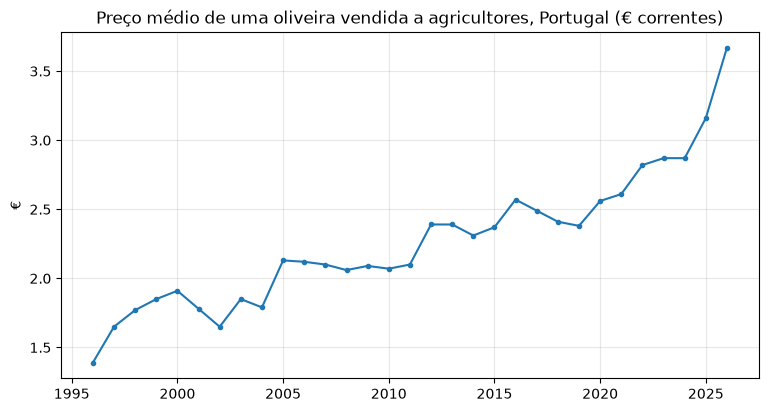

In [17]:
def ler_preco_nacional(caminho):
    linhas = ler_linhas(caminho)
    if "Preço médio das árvores" not in " ".join(linhas[:12]):
        return None
    anos = None
    for l in linhas:
        c = l.split(";")
        if anos is None:
            ys = [x.strip() for x in c[1:] if x.strip()]
            if len(ys) > 3 and all(re.fullmatch(r"\d{4}", y) for y in ys):
                anos = [int(y) for y in ys]
            continue
        if c[0].strip().startswith("PT:"):
            vals = [limpar_valor(x)[0] for x in c[1:1 + len(anos)]]
            return pd.Series(vals, index=anos, name="preco_medio_eur").sort_index()
    return None

precos = [s for s in (ler_preco_nacional(p) for p in glob.glob(os.path.join(DATA_DIR, "*.csv"))) if s is not None]
if precos:
    preco = precos[0]
    preco.plot(marker="o", ms=3, title="Preço médio de uma oliveira vendida a agricultores, Portugal (€ correntes)")
    plt.ylabel("€"); plt.show()
    nacional_com_preco = nac.join(preco, how="outer"); nacional_com_preco.to_csv(os.path.join(OUT_DIR, "nacional_ano_completo.csv"))
else:
    print("CSV de preço não encontrado (opcional).")

## 10. Próximos passos
- [ ] Discutir com os orientadores o resultado da seção 8: o que estas vendas realmente medem, e se outra variável (por exemplo, área de olival ou plantações novas) seria melhor indicador estrutural.
- [ ] Baixar **azeitona oleificada (t) em NUTS 2024 (NUTS 2)** e o rendimento NUTS 2024, para montar o painel regional completo (7 regiões) com a mesma geografia das árvores.
- [ ] Ver na metainformação do INE o significado do `*`, a cobertura do inquérito de viveiros e a diferença entre "local de proveniência" e "localização geográfica".
- [ ] Usar os gráficos das seções 4, 5, 7 e 8 na **apresentação intermédia (E1, até 06/12)**.
- [ ] Depois: regressões com desfasamentos, efeitos fixos por região e random forest/XGBoost com validação cruzada temporal (T3).

Arquivos gerados em `dados_tratados/`: `painel_regiao_ano.csv`, `nacional_ano.csv`, `oliveiras_vendidas.csv` e `nacional_ano_completo.csv`.